**Long Zhang** | GitHub: `zl535992549-cell` | USC ID: `8768388438`

**1(a)**

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from threadpoolctl import threadpool_limits

SEED = 42
LABELS = ['Family', 'Genus', 'Species']
DATA_PATH = Path('../data/Frogs_MFCCs.csv')
if not DATA_PATH.is_file():
    DATA_PATH = Path('data/Frogs_MFCCs.csv')
df = pd.read_csv(DATA_PATH)
X = df.filter(regex=r'^MFCCs_').to_numpy(dtype=float)
y = df[LABELS].reset_index(drop=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y['Species']
)
print(f'Data: {X.shape} | Training: {X_train.shape[0]} | Testing: {X_test.shape[0]}')
print('Classes:', {label: y[label].nunique() for label in LABELS})

Data: (7195, 22) | Training: 5036 | Testing: 2159
Classes: {'Family': 4, 'Genus': 8, 'Species': 10}


**1(b)(i)** Exact: all labels correct. Distance: errors/row. Loss: errors/labels. Score: 1 − loss.

In [2]:
def multilabel_metrics(y_true, y_pred):
    true = np.asarray(y_true)
    pred = np.asarray(y_pred)
    wrong = true != pred
    distances = wrong.sum(axis=1)
    return {
        'Exact match': np.mean(distances == 0),
        'Hamming distance': distances.mean(),
        'Hamming score': 1.0 - wrong.mean(),
        'Hamming loss': wrong.mean(),
    }

CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def report_models(models):
    predictions = pd.DataFrame({label: models[label].predict(X_test) for label in LABELS})
    scores = multilabel_metrics(y_test[LABELS], predictions[LABELS])
    selection = pd.DataFrame([{
        'Label': label,
        'Best parameters': models[label].best_params_,
        'CV accuracy': models[label].best_score_,
        'Test accuracy': np.mean(predictions[label].to_numpy() == y_test[label].to_numpy()),
    } for label in LABELS])
    return selection, scores


**1(b)(ii)**

In [3]:
rbf_models = {}
with threadpool_limits(limits=2):
    for label in LABELS:
        estimator = Pipeline([
            ('scale', StandardScaler()),
            ('clf', OneVsRestClassifier(SVC(kernel='rbf'))),
        ])
        search = GridSearchCV(
            estimator,
            {'clf__estimator__C': [0.1, 1, 10, 100],
             'clf__estimator__gamma': [0.001, 0.01, 0.1]},
            cv=CV, scoring='accuracy', n_jobs=1, refit=True,
        )
        search.fit(X_train, y_train[label])
        rbf_models[label] = search
rbf_selection, rbf_scores = report_models(rbf_models)
print(rbf_selection.to_string(index=False))

  Label                                           Best parameters  CV accuracy  Test accuracy
 Family {'clf__estimator__C': 100, 'clf__estimator__gamma': 0.01}     0.989873       0.992589
  Genus   {'clf__estimator__C': 10, 'clf__estimator__gamma': 0.1}     0.988483       0.990736
Species   {'clf__estimator__C': 10, 'clf__estimator__gamma': 0.1}     0.986498       0.988421


**1(b)(iii)**

In [4]:
l1_models = {}
with threadpool_limits(limits=2):
    for label in LABELS:
        estimator = Pipeline([
            ('scale', StandardScaler()),
            ('clf', LinearSVC(penalty='l1', loss='squared_hinge',
                              dual=False, tol=0.01, max_iter=3000,
                              random_state=SEED)),
        ])
        search = GridSearchCV(
            estimator, {'clf__C': [0.01, 0.1, 1, 10]},
            cv=CV, scoring='accuracy', n_jobs=1, refit=True,
        )
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', category=UserWarning)
            search.fit(X_train, y_train[label])
        l1_models[label] = search
l1_selection, l1_scores = report_models(l1_models)
print(l1_selection.to_string(index=False))

  Label Best parameters  CV accuracy  Test accuracy
 Family  {'clf__C': 10}     0.933479       0.940250
  Genus  {'clf__C': 10}     0.951549       0.948124
Species  {'clf__C': 10}     0.956711       0.959704


**1(b)(iv)**

In [5]:
smote_models = {}
with threadpool_limits(limits=2):
    for label in LABELS:
        estimator = ImbPipeline([
            ('scale', StandardScaler()),
            ('smote', SMOTE(random_state=SEED, k_neighbors=5)),
            ('clf', LinearSVC(penalty='l1', loss='squared_hinge',
                              dual=False, tol=0.01, max_iter=3000,
                              random_state=SEED)),
        ])
        search = GridSearchCV(
            estimator, {'clf__C': [0.01, 0.1, 1, 10]},
            cv=CV, scoring='accuracy', n_jobs=1, refit=True,
        )
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', category=UserWarning)
            search.fit(X_train, y_train[label])
        smote_models[label] = search
l1_smote_selection, l1_smote_scores = report_models(smote_models)
print(l1_smote_selection.to_string(index=False))
summary_svm = pd.DataFrame([rbf_scores, l1_scores, l1_smote_scores],
    index=['RBF SVM', 'L1 Linear SVM', 'L1 Linear SVM + SMOTE'])
print('\nComparison:')
print(summary_svm.round(5).to_string())

  Label Best parameters  CV accuracy  Test accuracy
 Family  {'clf__C': 10}     0.912629       0.912923
  Genus  {'clf__C': 10}     0.913624       0.917091
Species   {'clf__C': 1}     0.953137       0.962946

Comparison:
                       Exact match  Hamming distance  Hamming score  Hamming loss
RBF SVM                    0.98425           0.02825        0.99058       0.00942
L1 Linear SVM              0.91709           0.15192        0.94936       0.05064
L1 Linear SVM + SMOTE      0.86058           0.20704        0.93099       0.06901


**Conclusion:** RBF best; SMOTE worsened overall accuracy. $\sigma=1/\sqrt{2\gamma}$: 7.071 (Family), 2.236 (Genus, Species).

**2(a)**

In [6]:
def choose_k(data, random_state, sample_size=500):
    rng = np.random.default_rng(random_state)
    sample = data[rng.choice(len(data), size=min(sample_size, len(data)), replace=False)]
    best_k, best_score = None, -np.inf
    for k in range(2, 51):
        estimate = MiniBatchKMeans(n_clusters=k, n_init=3,
            batch_size=256, max_iter=100, random_state=random_state)
        group = estimate.fit_predict(sample)
        if len(np.unique(group)) < 2:
            continue
        score = silhouette_score(sample, group)
        if score > best_score:
            best_k, best_score = k, score
    return best_k, best_score

true_labels = y[LABELS].to_numpy()
monte_carlo_rows = []
first_cluster_majorities = None
with threadpool_limits(limits=2):
    for run in range(50):
        k, sil = choose_k(X, random_state=1000 + run)
        cluster_ids = KMeans(n_clusters=k, n_init=10,
            random_state=1000 + run).fit_predict(X)
        assigned = np.empty(true_labels.shape, dtype=object)
        majority_rows = []
        for cluster_id in np.unique(cluster_ids):
            members = (cluster_ids == cluster_id)
            majority = []
            for j in range(len(LABELS)):
                unique, counts = np.unique(true_labels[members, j], return_counts=True)
                majority.append(unique[np.argmax(counts)])
            assigned[members] = majority
            majority_rows.append({'Cluster': cluster_id, 'Size': members.sum(),
                                  **dict(zip(LABELS, majority))})
        if run == 0:
            first_cluster_majorities = pd.DataFrame(majority_rows)
        monte_carlo_rows.append({'Run': run + 1, 'k': k, 'Silhouette': sil,
                                 **multilabel_metrics(true_labels, assigned)})
mc = pd.DataFrame(monte_carlo_rows)
print('Chosen k (frequency):')
print(mc['k'].value_counts().sort_index().to_string())
print('Runs completed:', len(mc))

Chosen k (frequency):
k
2     1
3     7
4    23
5    10
6     7
7     2
Runs completed: 50


**2(b)**

In [7]:
print('Run 1 cluster-majority labels:')
print(first_cluster_majorities.to_string(index=False))

Run 1 cluster-majority labels:
 Cluster  Size          Family     Genus                Species
       0  1788         Hylidae Hypsiboas      HypsiboasCordobae
       1  3560 Leptodactylidae Adenomera AdenomeraHylaedactylus
       2  1847         Hylidae Hypsiboas      HypsiboasCordobae


**2(c)**

In [8]:
mc_stats = mc[['Hamming distance', 'Hamming score', 'Hamming loss']].agg(['mean', 'std'])
print('50-run metrics (sample standard deviation):')
print(mc_stats.round(6).to_string())

50-run metrics (sample standard deviation):
      Hamming distance  Hamming score  Hamming loss
mean          0.647975       0.784008      0.215992
std           0.132845       0.044282      0.044282


**3(a–b)**

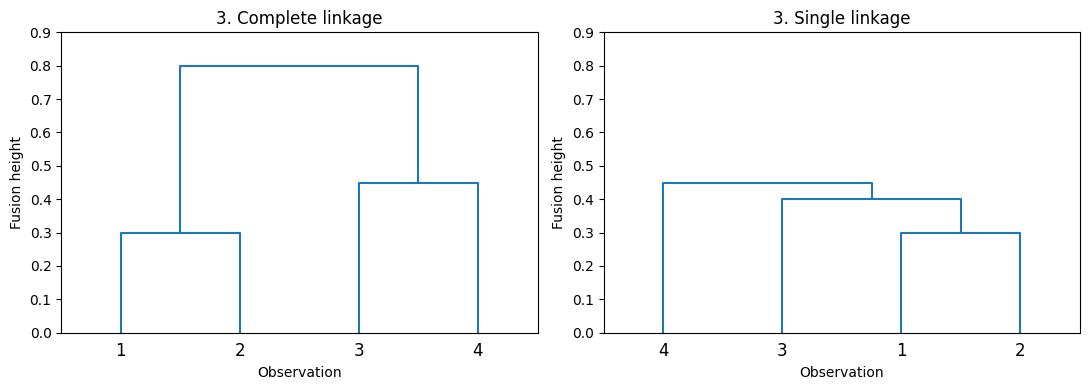

Complete fusion heights: [0.3  0.45 0.8 ]
Single fusion heights: [0.3  0.4  0.45]


In [9]:
D = np.array([[0.00, 0.30, 0.40, 0.70],
              [0.30, 0.00, 0.50, 0.80],
              [0.40, 0.50, 0.00, 0.45],
              [0.70, 0.80, 0.45, 0.00]])
complete = linkage(squareform(D), method='complete')
single = linkage(squareform(D), method='single')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, matrix, name in zip(axes, [complete, single], ['Complete', 'Single']):
    dendrogram(matrix, labels=['1', '2', '3', '4'], ax=ax,
               color_threshold=0, above_threshold_color='C0')
    ax.set(title=f'3. {name} linkage', xlabel='Observation', ylabel='Fusion height')
    ax.set_ylim(0, 0.9)
plt.tight_layout()
plt.show()
print('Complete fusion heights:', complete[:, 2])
print('Single fusion heights:', single[:, 2])

**3(c–d)**

In [10]:
for name, matrix in [('Complete', complete), ('Single', single)]:
    groups = fcluster(matrix, t=2, criterion='maxclust')
    clusters = [(np.where(groups == group)[0] + 1).tolist() for group in np.unique(groups)]
    print(f'{name}: {clusters}')

Complete: [[1, 2], [3, 4]]
Single: [[1, 2, 3], [4]]


**3(e)**

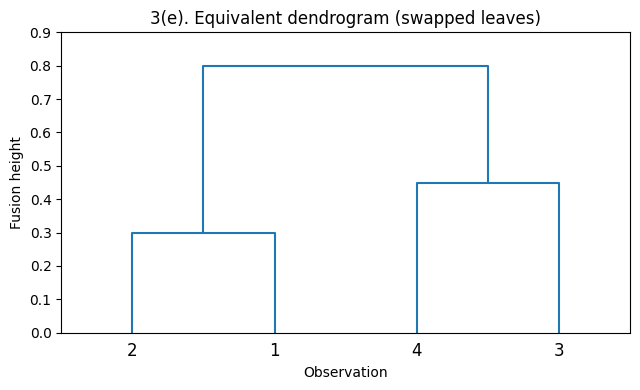

In [11]:
equivalent = complete.copy()
for row_index in (0, 1):
    equivalent[row_index, :2] = equivalent[row_index, :2][::-1]
plt.figure(figsize=(6.5, 4))
dendrogram(equivalent, labels=['1', '2', '3', '4'],
           color_threshold=0, above_threshold_color='C0')
plt.title('3(e). Equivalent dendrogram (swapped leaves)')
plt.xlabel('Observation')
plt.ylabel('Fusion height')
plt.ylim(0, 0.9)
plt.tight_layout()
plt.show()

Swapping sibling branches preserves distances and clusters.

**References:** UCI Anuran Calls; scikit-learn; imbalanced-learn; ISLR Ch. 12; ChatGPT.